<a href="https://colab.research.google.com/github/Eldonwhiteley/MRI_Project/blob/main/src/HDF5_Viewing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HDF5 Viewing Example
**Authors:** Eldon Whiteley, Gail Kinder, Dylan Bjorum

This notebook demonstrates how to interface with the `HDF5View` class (defined in `hdf5_view.py`) to easily load, inspect, and interactively visualize 3D MRI scans (`.im`) and their multi-channel segmentation masks (`.seg`).

In [1]:
# Install dependencies if running in Colab or a fresh environment
%pip install -q h5py matplotlib numpy ipywidgets


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys

# Ensure Python can import hdf5_view whether running from root, src/, or Colab
for candidate in [".", "src", "..", "../src"]:
    if os.path.isfile(os.path.join(candidate, "hdf5_view.py")):
        if candidate not in sys.path:
            sys.path.insert(0, os.path.abspath(candidate))
        break

from hdf5_view import HDF5View
print("Successfully imported HDF5View!")

Successfully imported HDF5View!


## 1. Discover Data Pairs
Use `HDF5View.find_pairs(data_dir)` to automatically locate matching `(.im, .seg)` file pairs in your dataset folder. This helper automatically excludes macOS `._*` AppleDouble metadata files.

In [3]:
from setup_data import extract_archives

# Automatically extract archives into data/ if data is not already present
dest_dir = "data" if os.path.isdir("data") or not os.path.isdir("../data") else "../data"
extract_archives(dest_dir=dest_dir)

# Locate dataset directory
possible_data_dirs = [
    "data/train-shifted",
    "../data/train-shifted",
    "data/train-shifted/train-shifted",
    "../data/train-shifted/train-shifted",
]
data_dir = next((d for d in possible_data_dirs if os.path.isdir(d)), None)
if data_dir is None:
    raise FileNotFoundError("Could not find data folder. Check relative paths.")

pairs = HDF5View.find_pairs(data_dir)
print(f"Found {len(pairs)} matching (.im, .seg) pairs in '{data_dir}'.
")

sample_im, sample_seg = pairs[0]
print(f"First Sample:
  Image: {sample_im}
  Mask:  {sample_seg}")

Found 120 matching (.im, .seg) pairs in '../data/train-shifted'.

First Sample:
  Image: ../data/train-shifted/train_001_V00.im
  Mask:  ../data/train-shifted/train_001_V00.seg


## 2. Initialize `HDF5View`
Create an instance of `HDF5View`. By default, it inspects metadata lazily without loading the entire 225 MB volume into RAM.

In [4]:
viewer = HDF5View(sample_im, sample_seg)
print("Viewer instance:", viewer)
print("\nDetailed Info:")
for key, val in viewer.info().items():
    print(f"  {key}: {val}")

Viewer instance: <HDF5View: im_shape=(384, 384, 160), seg_shape=(384, 384, 160, 6), slices=160>

Detailed Info:
  image_file: train_001_V00.im
  image_shape: (384, 384, 160)
  image_dtype: float32
  num_slices: 160
  has_segmentation: True
  seg_file: train_001_V00.seg
  seg_shape: (384, 384, 160, 6)
  seg_dtype: uint8
  num_channels: 6


## 3. Retrieve a Single Slice (Direct from Disk or Cache)
Use `viewer.get_slice(slice_idx)` to fetch an individual 2D MRI slice and its 6 segmentation channels.

In [5]:
slice_number = 95
im_slice, seg_slice = viewer.get_slice(slice_number)

print(f"Slice {slice_number}:")
print(f"  MRI 2D Slice shape: {im_slice.shape}, dtype: {im_slice.dtype}")
print(f"  Segmentation shape: {seg_slice.shape}, dtype: {seg_slice.dtype}")

# Check active channels in this slice
print("  Active channels:")
for c in range(seg_slice.shape[-1]):
    cnt = seg_slice[:, :, c].sum()
    if cnt > 0:
        print(f"    - Ch {c} ({viewer.channel_labels[c]}): {cnt} voxels")

Slice 95:
  MRI 2D Slice shape: (384, 384), dtype: float32
  Segmentation shape: (384, 384, 6), dtype: uint8
  Active channels:
    - Ch 0 (Femoral Cartilage): 1587 voxels
    - Ch 1 (Lateral Tibial Cartilage): 453 voxels
    - Ch 3 (Patellar Cartilage): 378 voxels
    - Ch 4 (Lateral Meniscus): 466 voxels


## 4. Static Multi-Panel Visualization
`viewer.plot_slice()` displays:
1. The raw grayscale MRI slice.
2. The composite color-coded overlay.
3. Individual subplots for each of the 6 tissue masks with voxel counts.

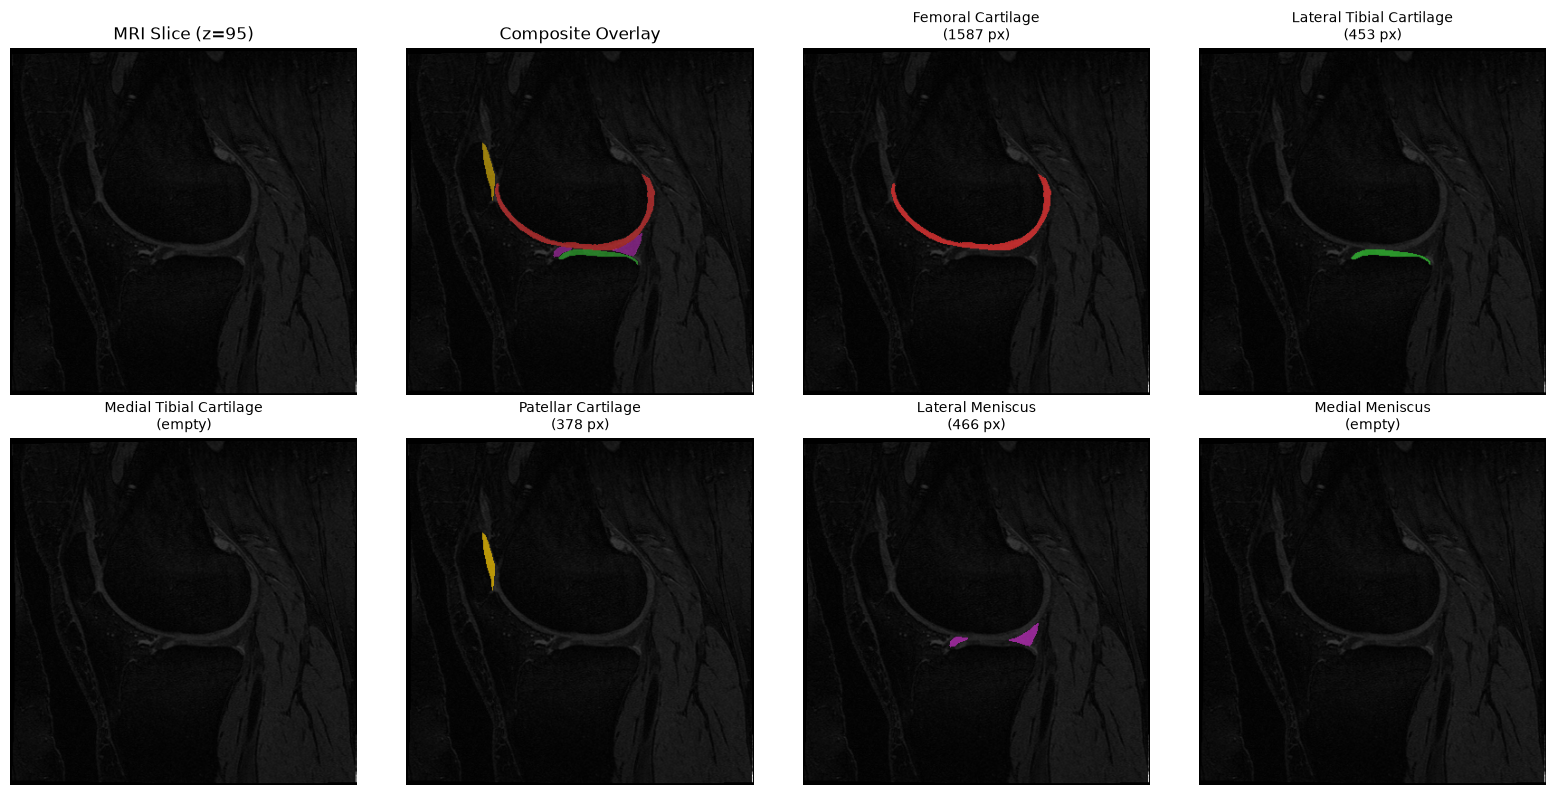

In [6]:
# Plot slice 95 (or try 60, 75, etc.)
fig = viewer.plot_slice(slice_idx=95, alpha=0.55)
import matplotlib.pyplot as plt
plt.show()

## 5. Interactive Slice Viewer
`viewer.interactive_viewer()` caches the 3D volume in RAM and launches an interactive slider widget with real-time slice scrolling and opacity controls.

In [7]:
# Launch interactive slider (scroll through all 160 slices)
viewer.interactive_viewer(default_slice=75, default_alpha=0.5)

interactive(children=(IntSlider(value=75, continuous_update=False, description='Slice:', max=159), Checkbox(va…

## 6. Orthogonal Multi-Planar Views (Sagittal, Coronal, Axial)
Because the scan is a 3D volumetric array, `viewer.plot_orthogonal()` reslices it across all three anatomical planes.

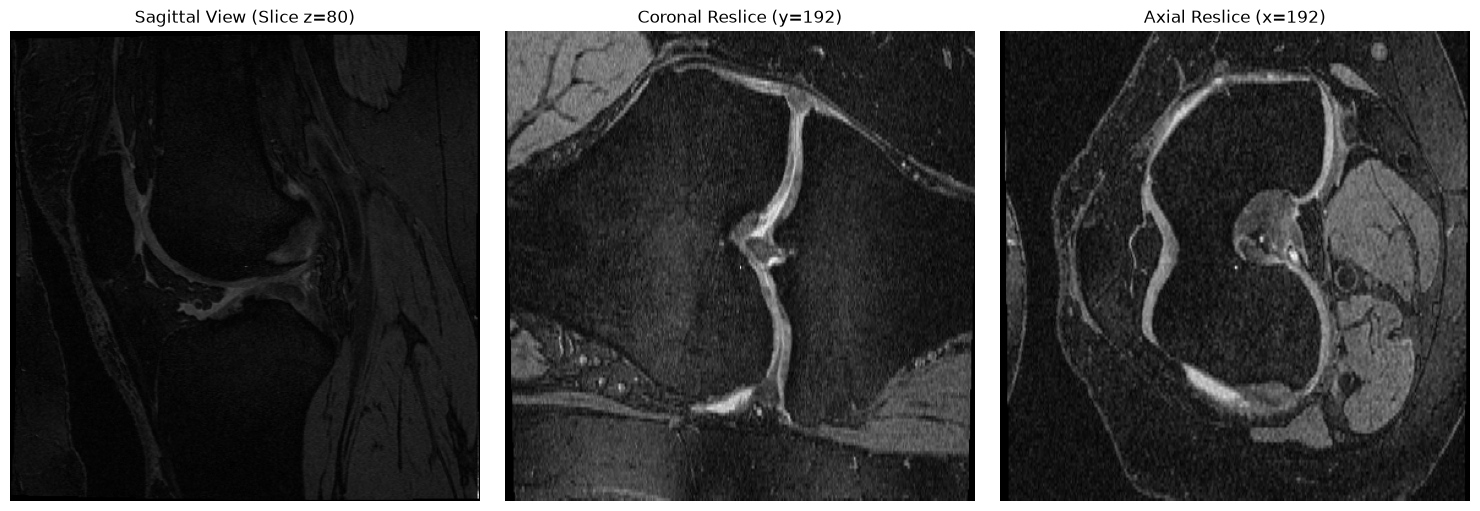

In [8]:
fig_ortho = viewer.plot_orthogonal()
plt.show()